# Análise exploratória de dados climáticos do Rio Grande do Sul

## 1. Configuração do ambiente

Obs.: O download do ERA5-Land exige credenciais válidas do Copernicus Climate Data Store configuradas no arquivo `~/.cdsapirc`.

In [ ]:
from pathlib import Path
import io
import os
import zipfile
import warnings
import cdsapi
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import rioxarray
import seaborn as sns
import xarray as xr
from shapely.geometry import mapping

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

ANO_INICIAL = 1990
ANO_FINAL = 2025
ANOS = [str(ano) for ano in range(ANO_INICIAL, ANO_FINAL + 1)]
MESES = [f"{mes:02d}" for mes in range(1, 13)]

PASTA_DADOS = Path("dados_era5")
PASTA_DADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_DOWNLOAD = PASTA_DADOS / f"era5_land_rs_{ANO_INICIAL}_{ANO_FINAL}_mensal.nc"
ARQUIVO_EXTRAIDO = PASTA_DADOS / "netcdf_extraido"

Período configurado: 1990–2025 (36 anos).


## Obtenção dos dados do ERA5-Land

Nota-se, abaixo, que a área solicitada à API é deliberadamente maior que o Rio Grande do Sul. O recorte definitivo será realizado posteriormente com a malha fornecida pelo IBGE, para evitar que o retângulo inicial de download ignore algum grid que deveria pertencer aoo estado.

A API recebe a área na ordem `[Norte, Oeste, Sul, Leste]`. O intervalo de anos inclui 1990 e 2025.

In [ ]:
AREA_DOWNLOAD = [-25.5, -59.5, -35.5, -47.5]

if not ARQUIVO_DOWNLOAD.exists():
    print("Solicitando dados mensais ao Copernicus Climate Data Store...")
    cliente_cds = cdsapi.Client()
    cliente_cds.retrieve(
        "reanalysis-era5-land-monthly-means",
        {
            "product_type": "monthly_averaged_reanalysis",
            "variable": ["2m_temperature", "total_precipitation"],
            "year": ANOS,
            "month": MESES,
            "time": "00:00",
            "area": AREA_DOWNLOAD,
            "data_format": "netcdf",
            "download_format": "unarchived",
        },
        str(ARQUIVO_DOWNLOAD),
    )
    print(f"Download concluído: {ARQUIVO_DOWNLOAD}")
else:
    print(f"Arquivo já existe; o download foi ignorado: {ARQUIVO_DOWNLOAD}")

Solicitando dados mensais ao Copernicus Climate Data Store...


2026-10-28 19:29:55,745 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
Recovering from HTTP error [502 Bad Gateway], attempt 1 of 500
Retrying in 120 seconds
2026-10-28 19:31:59,216 INFO Request ID is 1f901dd4-4300-4b0d-829a-0747b67156ef
2026-10-28 19:31:59,493 INFO status has been updated to successful


fc60dc0c41b274f09fe3a3ee7bce1027.nc:   0%|          | 0.00/16.9M [00:00<?, ?B/s]

Download concluído: dados_era5\era5_land_rs_1990_2025_mensal.nc


### Abrir o NetCDF e verificar o período

Dependendo da resposta da API, o arquivo recebido pode ser um NetCDF diretamente ou um ZIP que contém um ou mais NetCDFs

In [ ]:
def localizar_netcdf(caminho_download: Path) -> Path:
    """Retorna o caminho de um NetCDF, extraindo o download se ele for ZIP."""
    if not caminho_download.exists():
        raise FileNotFoundError(
            f"Arquivo não encontrado: {caminho_download}. Execute primeiro a célula de download."
        )

    if zipfile.is_zipfile(caminho_download):
        ARQUIVO_EXTRAIDO.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(caminho_download) as arquivo_zip:
            arquivo_zip.extractall(ARQUIVO_EXTRAIDO)
        candidatos = list(ARQUIVO_EXTRAIDO.rglob("*.nc"))
        if not candidatos:
            raise FileNotFoundError("O ZIP foi extraído, mas nenhum arquivo .nc foi encontrado.")
        return candidatos[0]

    # Se não for ZIP, tenta abrir o próprio arquivo como NetCDF.
    return caminho_download


caminho_nc = localizar_netcdf(ARQUIVO_DOWNLOAD)
ds = xr.open_dataset(caminho_nc)

if "valid_time" in ds.dims or "valid_time" in ds.coords:
    ds = ds.rename({"valid_time": "time"})


renomear = {}
if "lat" in ds.coords and "latitude" not in ds.coords:
    renomear["lat"] = "latitude"
if "lon" in ds.coords and "longitude" not in ds.coords:
    renomear["lon"] = "longitude"
if renomear:
    ds = ds.rename(renomear)

ds = ds.sortby("time")
ds = ds.sel(time=slice(f"{ANO_INICIAL}-01-01", f"{ANO_FINAL}-12-31"))
meses_encontrados = pd.DatetimeIndex(ds.time.values).to_period("M").unique()
meses_esperados = pd.period_range(
    f"{ANO_INICIAL}-01", f"{ANO_FINAL}-12", freq="M"
)
meses_ausentes = meses_esperados.difference(meses_encontrados)

print(ds)
print(f"Meses encontrados: {len(meses_encontrados)} de {len(meses_esperados)}.")

<xarray.Dataset> Size: 42MB
Dimensions:    (time: 432, latitude: 101, longitude: 121)
Coordinates:
  * time       (time) datetime64[ns] 3kB 1990-01-01 1990-02-01 ... 2025-12-01
    expver     (time) <U4 7kB ...
  * latitude   (latitude) float64 808B -25.5 -25.6 -25.7 ... -35.3 -35.4 -35.5
  * longitude  (longitude) float64 968B -59.5 -59.4 -59.3 ... -47.7 -47.6 -47.5
    number     int64 8B ...
Data variables:
    t2m        (time, latitude, longitude) float32 21MB ...
    tp         (time, latitude, longitude) float32 21MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-28T00:45 GRIB to CDM+CF via cfgrib-0.9.1...
Meses encontrados: 432 de 432.


## Transformação das variáveis e unidades

A temperatura `t2m` é convertida de kelvin para graus Celsius. No produto de médias mensais diárias do ERA5-Land, `tp` é representada como precipitação média diária em metros de equivalente de água; por isso, o total mensal é obtido multiplicando por 1.000 e pelo número de dias daquele mês.

A unidade da precipitação será **mm/mês**. Totais anuais serão calculados somando os 12 totais mensais de cada ano.

In [5]:
ds["t2m_celsius"] = ds["t2m"] - 273.15
dias_no_mes = ds["time"].dt.days_in_month
ds["tp_mm_mes"] = ds["tp"] * 1000 * dias_no_mes

ds["t2m_celsius"].attrs.update(
    long_name="Temperatura média mensal do ar a 2 m", units="°C"
)
ds["tp_mm_mes"].attrs.update(
    long_name="Precipitação total mensal", units="mm/month"
)

display(ds[["t2m_celsius", "tp_mm_mes"]])

<xarray.Dataset> Size: 63MB
Dimensions:      (time: 432, latitude: 101, longitude: 121)
Coordinates:
  * time         (time) datetime64[ns] 3kB 1990-01-01 1990-02-01 ... 2025-12-01
    expver       (time) <U4 7kB ...
  * latitude     (latitude) float64 808B -25.5 -25.6 -25.7 ... -35.3 -35.4 -35.5
  * longitude    (longitude) float64 968B -59.5 -59.4 -59.3 ... -47.6 -47.5
    number       int64 8B ...
Data variables:
    t2m_celsius  (time, latitude, longitude) float32 21MB 27.77 27.71 ... nan
    tp_mm_mes    (time, latitude, longitude) float64 42MB 127.9 128.6 ... nan
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-28T00:45 GRIB to CDM+CF via cfgrib-0.9.1...

## Malha do Rio Grande do Sul e recorte espacial

abaixo, a malha estadual do IBGE é baixada e sua geometria é usada para recortar a grade climática. Escolhi usar uma área maior solicitada à API para ter certeza de que pegaria todas as células representando o estado do RS.

In [ ]:
URL_RS = (
    "https://servicodados.ibge.gov.br/api/v3/malhas/estados/RS"
    "?formato=application/vnd.geo+json"
)

resposta = requests.get(URL_RS, timeout=120)
resposta.raise_for_status()
rs_poly = gpd.read_file(io.BytesIO(resposta.content))
ds = ds.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude", inplace=False)
ds = ds.rio.write_crs("EPSG:4326", inplace=False)

print("Limites da malha do RS:", rs_poly.total_bounds)
print(
    "Limites da grade baixada:",
    [
        float(ds.longitude.min()), float(ds.latitude.min()),
        float(ds.longitude.max()), float(ds.latitude.max())
    ],
)

ds_rs = ds.rio.clip(
    rs_poly.geometry.apply(mapping),
    rs_poly.crs,
    drop=True,
    all_touched=False,
)

print("Recorte do RS concluído.")
print("Dimensões do recorte:", dict(ds_rs.sizes))
print("Células com temperatura válida:", int(ds_rs["t2m_celsius"].isel(time=0).count().values))

Limites da malha do RS: [-57.6497 -33.7508 -49.6914 -27.0823]
Limites da grade baixada: [-59.5, -35.5, -47.5, -25.5]
Recorte do RS concluído.
Dimensões do recorte: {'time': 432, 'latitude': 66, 'longitude': 78}
Células com temperatura válida: 2473


## Malha municipal e tabela de nomes

A malha municipal será usada para agregar os dados por município e para comparar escalas geográficas.

In [ ]:
URL_MUNICIPIOS = (
    "https://servicodados.ibge.gov.br/api/v3/malhas/estados/RS"
    "?formato=application/vnd.geo+json&intrarregiao=municipio"
)
URL_NOMES_MUNICIPIOS = (
    "https://servicodados.ibge.gov.br/api/v1/localidades/estados/RS/municipios"
)

resp_malha = requests.get(URL_MUNICIPIOS, timeout=120)
resp_malha.raise_for_status()
rs_mun = gpd.read_file(io.BytesIO(resp_malha.content))
resp_nomes = requests.get(URL_NOMES_MUNICIPIOS, timeout=120)
resp_nomes.raise_for_status()
nomes_df = pd.DataFrame(resp_nomes.json())

if "codarea" not in rs_mun.columns:
    raise KeyError(f"Campo 'codarea' não encontrado. Campos recebidos: {list(rs_mun.columns)}")
rs_mun["codarea"] = rs_mun["codarea"].astype(str)
nomes_df["id"] = nomes_df["id"].astype(str)

rs_mun = rs_mun.merge(
    nomes_df[["id", "nome"]],
    left_on="codarea",
    right_on="id",
    how="left",
    validate="one_to_one",
)
rs_mun = rs_mun.to_crs("EPSG:4326")

## Funções para resumir e mapear as variáveis

- Temperatura média histórica: média dos valores mensais de temperatura de 1990 a 2025.
- Precipitação média anual: soma da precipitação de cada ano e, depois, média dos totais anuais de 1990 a 2025.
- Variabilidade da temperatura: desvio-padrão dos valores mensais e desvio-padrão das médias anuais, apresentados separadamente.
- Variabilidade da precipitação: desvio-padrão dos totais anuais de precipitação


In [ ]:
def resumir_serie_regional(serie: xr.Dataset) -> dict:
    """Calcula estatísticas de uma série temporal já agregada espacialmente."""
    temp_mensal = serie["t2m_celsius"]
    precip_mensal = serie["tp_mm_mes"]

    temp_anual = temp_mensal.groupby("time.year").mean("time", skipna=True)
    precip_anual = precip_mensal.groupby("time.year").sum("time", skipna=True)

    return {
        "Temp_Media_C": float(temp_mensal.mean("time", skipna=True).values),
        "Precip_Media_Anual_mm": float(precip_anual.mean("year", skipna=True).values),
        "Temp_DesvioPadrao_Mensal_C": float(temp_mensal.std("time", skipna=True).values),
        "Temp_DesvioPadrao_Anual_C": float(temp_anual.std("year", skipna=True).values),
        "Precip_DesvioPadrao_Anual_mm": float(precip_anual.std("year", skipna=True).values),
    }


def extrair_serie_poligono(ds_base: xr.Dataset, geometria, crs) -> xr.Dataset:
    """Calcula a média espacial mensal dentro de um polígono.
    """
    geom = [mapping(geometria)]
    try:
        recorte = ds_base.rio.clip(
            geom, crs, drop=True, all_touched=True
        )
        n_celulas = int(recorte["t2m_celsius"].isel(time=0).count().values)
        if n_celulas == 0:
            raise ValueError("O recorte não contém células válidas na primeira data.")
        serie = recorte[["t2m_celsius", "tp_mm_mes"]].mean(
            dim=["latitude", "longitude"], skipna=True
        )
        return serie
    except Exception as exc:
        sem_dados = (
            exc.__class__.__name__ == "NoDataInBounds"
            or "No data found in bounds" in str(exc)
            or "não contém células válidas" in str(exc)
        )
        if not sem_dados:
            raise

        ponto = geometria.representative_point()
        lat = float(ponto.y)
        lon = float(ponto.x)
        ponto_serie = ds_base[["t2m_celsius", "tp_mm_mes"]].sel(
            latitude=lat, longitude=lon, method="nearest"
        )
        warnings.warn(
            "O polígono não intersectou células da grade no recorte; "
            "foi usada a célula ERA5-Land mais próxima do ponto representativo. "
            RuntimeWarning,
        )
        return ponto_serie


def criar_tabela_regional(ds_base: xr.Dataset, regioes: gpd.GeoDataFrame,
                          coluna_nome: str, rotulo: str):
    """Retorna GeoDataFrame com indicadores e DataFrame longo com séries mensais."""
    regioes = regioes.to_crs("EPSG:4326").copy()
    regioes[rotulo] = regioes[coluna_nome].astype(str)
    estatisticas = []
    series = []

    for _, regiao in regioes.iterrows():
        nome = str(regiao[coluna_nome])
        serie = extrair_serie_poligono(ds_base, regiao.geometry, regioes.crs)
        stats = resumir_serie_regional(serie)
        stats[rotulo] = nome
        estatisticas.append(stats)

        df_serie = serie.to_dataframe().reset_index()
        df_serie[rotulo] = nome
        df_serie["Ano"] = df_serie["time"].dt.year
        df_serie["Mes"] = df_serie["time"].dt.month
        series.append(df_serie)

    tabela_stats = pd.DataFrame(estatisticas)
    regioes_resultado = regioes.merge(
        tabela_stats, on=rotulo, how="left", validate="one_to_one"
    )
    tabela_series = pd.concat(series, ignore_index=True)
    return regioes_resultado, tabela_stats, tabela_series


def plotar_mapa_duplo(gdf, coluna_temp, coluna_precip, nome_regiao, periodo):
    """Plota temperatura média e precipitação média anual por unidade territorial."""
    gdf = gdf.to_crs(rs_poly.crs).copy()
    limite_rs = rs_poly.geometry.unary_union
    gdf["geometry"] = gdf.geometry.intersection(limite_rs)
    fig, ax = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

    gdf.plot(
        column=coluna_temp, ax=ax[0], cmap="RdYlBu_r", legend=True,
        edgecolor="white", linewidth=0.35,
        legend_kwds={"label": "Temperatura média (°C)", "shrink": 0.78},
        missing_kwds={"color": "lightgrey", "label": "Sem dados"},
    )
    rs_poly.boundary.plot(ax=ax[0], color="black", linewidth=0.6)
    ax[0].set_title(f"Temperatura média — {nome_regiao}\n{periodo}")
    ax[0].set_axis_off()

    gdf.plot(
        column=coluna_precip, ax=ax[1], cmap="YlGnBu", legend=True,
        edgecolor="white", linewidth=0.35,
        legend_kwds={"label": "Precipitação média anual (mm/ano)", "shrink": 0.78},
        missing_kwds={"color": "lightgrey", "label": "Sem dados"},
    )
    rs_poly.boundary.plot(ax=ax[1], color="black", linewidth=0.6)
    ax[1].set_title(f"Precipitação média anual — {nome_regiao}\n{periodo}")
    ax[1].set_axis_off()

    plt.show()


## (1) Quais são os padrões espaciais de temperatura e precipitação no RS?

Primeiro, os mapas mostram os valores médios da grade ERA5-Land. Em seguida, calcula-se indicadores por município usando a média das células contidas em cada polígono municipal.

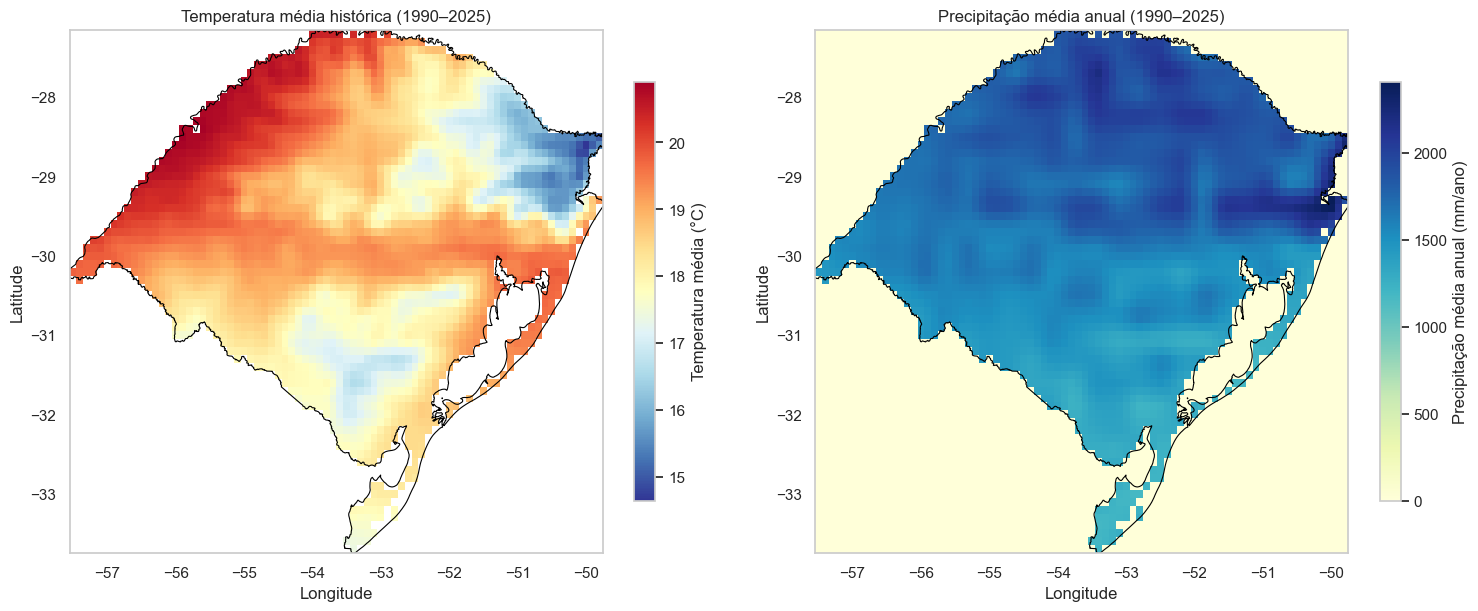

In [ ]:
dados_mapa = ds[["t2m_celsius", "tp_mm_mes"]].rio.clip(
    rs_poly.geometry.apply(mapping), rs_poly.crs, drop=True, all_touched=False
)
temp_media_espacial = dados_mapa["t2m_celsius"].mean("time", skipna=True)
precip_total_anual_grade = dados_mapa["tp_mm_mes"].groupby("time.year").sum("time", skipna=True)
precip_media_anual_grade = precip_total_anual_grade.mean("year", skipna=True)

fig, ax = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
temp_media_espacial.plot(
    ax=ax[0], cmap="RdYlBu_r",
    cbar_kwargs={"label": "Temperatura média (°C)", "shrink": 0.8}
)
rs_poly.boundary.plot(ax=ax[0], color="black", linewidth=0.8)
ax[0].set_title(f"Temperatura média histórica ({ANO_INICIAL}–{ANO_FINAL})")
ax[0].set_xlabel("Longitude")
ax[0].set_ylabel("Latitude")

precip_media_anual_grade.plot(
    ax=ax[1], cmap="YlGnBu",
    cbar_kwargs={"label": "Precipitação média anual (mm/ano)", "shrink": 0.8}
)
rs_poly.boundary.plot(ax=ax[1], color="black", linewidth=0.8)
ax[1].set_title(f"Precipitação média anual ({ANO_INICIAL}–{ANO_FINAL})")
ax[1].set_xlabel("Longitude")
ax[1].set_ylabel("Latitude")
plt.show()

### Indicadores por município

Para cada município, calcula-se a média espacial mensal a partir das células da grade dentro do polígono municipal. Em seguida, resume-se a série mensal no período completo.

O resultado é `gdf_municipios`, que contém a geometria municipal e os indicadores, e `df_municipios`, uma tabelapara consultar ou exportar os valores.

C:\Users\rober\AppData\Local\Temp\ipykernel_21840\976735841.py:100: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  limite_rs = rs_poly.geometry.unary_union


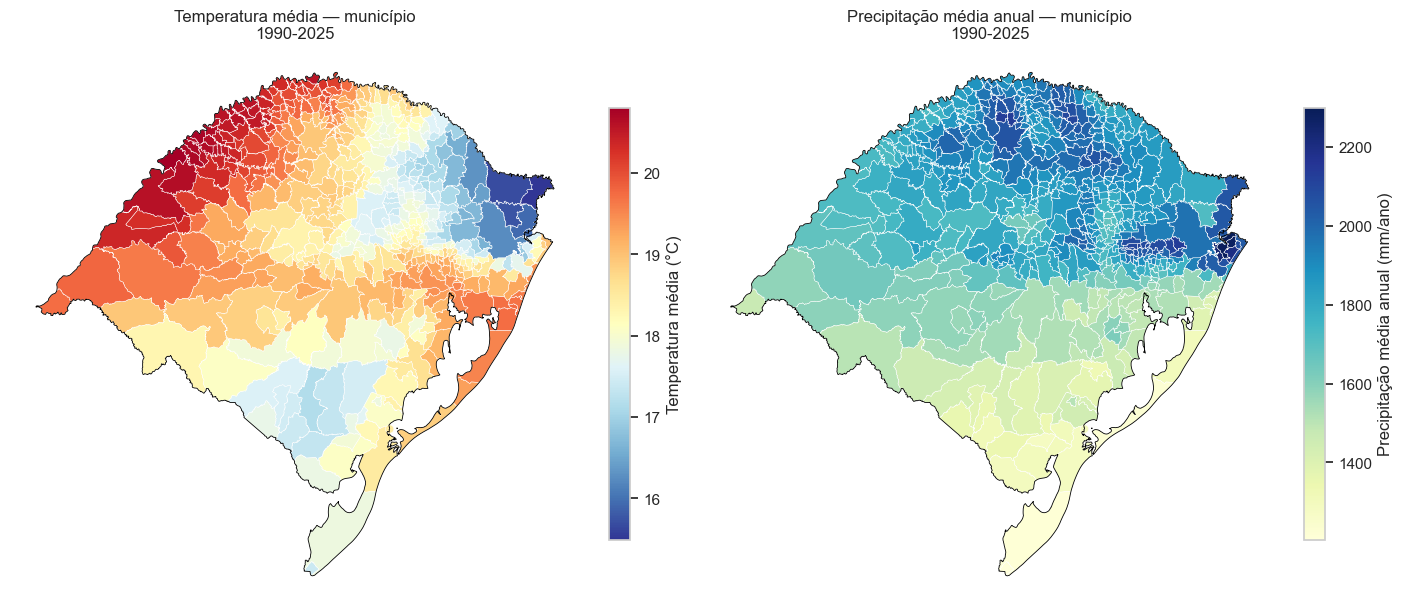

,Municipio,Temp_Media_C,Precip_Media_Anual_mm
397,São José dos Ausentes,15.488692,2051.758487
48,Bom Jesus,15.680490,1796.519668
223,Jaquirana,15.754480,1717.715157
67,Cambará do Sul,15.942424,2044.673491
384,São Francisco de Paula,16.248865,1969.406213


In [21]:
gdf_municipios, df_municipios, serie_municipios = criar_tabela_regional(
    ds, rs_mun, coluna_nome="nome", rotulo="Municipio"
)

plotar_mapa_duplo(
    gdf_municipios, "Temp_Media_C", "Precip_Media_Anual_mm",
    "município", f"{ANO_INICIAL}-{ANO_FINAL}"
)

display(
    df_municipios.sort_values("Temp_Media_C")
    [["Municipio", "Temp_Media_C", "Precip_Media_Anual_mm"]]
    .head()
)

## (2) Como temperatura e precipitação variam ao longo do ano e entre localidades?

A visualização abaixo utiliza quatro municípios selecionados e calcula a média espacial dentro de cada polígono.

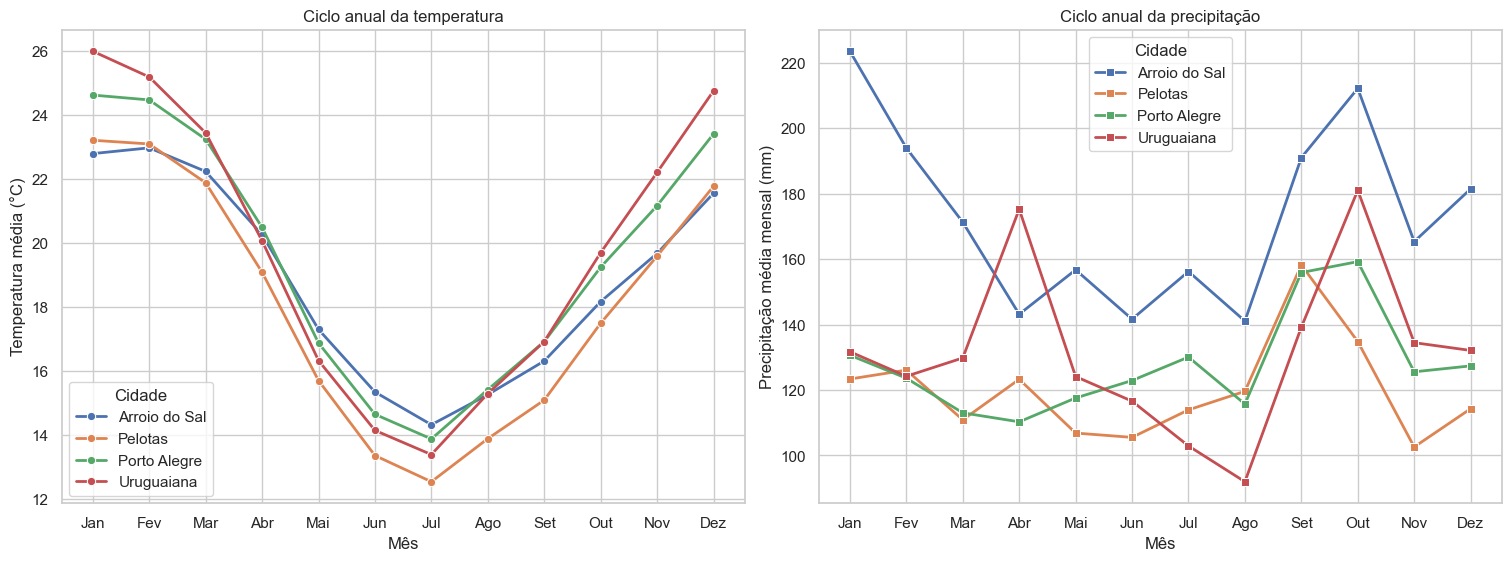

In [11]:
CIDADES_ALVO = ["Porto Alegre", "Pelotas", "Uruguaiana", "Arroio do Sal"]
gdf_cidades = rs_mun[rs_mun["nome"].isin(CIDADES_ALVO)].copy()

if set(CIDADES_ALVO) - set(gdf_cidades["nome"]):
    raise ValueError(f"Municípios não encontrados: {set(CIDADES_ALVO) - set(gdf_cidades['nome'])}")

series_cidades = []
for _, row in gdf_cidades.iterrows():
    serie = extrair_serie_poligono(ds, row.geometry, gdf_cidades.crs)
    df = serie.to_dataframe().reset_index()
    df["Cidade"] = row["nome"]
    df["Ano"] = df["time"].dt.year
    df["Mes"] = df["time"].dt.month
    series_cidades.append(df)

df_cidades_mensal = pd.concat(series_cidades, ignore_index=True)
MESES_NOMES = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
               "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
df_cidades_mensal["MesNome"] = pd.Categorical(
    df_cidades_mensal["Mes"].map(dict(enumerate(MESES_NOMES, start=1))),
    categories=MESES_NOMES, ordered=True
)

climatologia_cidades = (
    df_cidades_mensal.groupby(["Cidade", "Mes"], as_index=False, observed=False)
    [["t2m_celsius", "tp_mm_mes"]].mean()
)
climatologia_cidades["MesNome"] = pd.Categorical(
    climatologia_cidades["Mes"].map(dict(enumerate(MESES_NOMES, start=1))),
    categories=MESES_NOMES, ordered=True
)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
sns.lineplot(
    data=climatologia_cidades, x="MesNome", y="t2m_celsius",
    hue="Cidade", marker="o", linewidth=2, ax=ax[0]
)
ax[0].set_title("Ciclo anual da temperatura")
ax[0].set_xlabel("Mês")
ax[0].set_ylabel("Temperatura média (°C)")
ax[0].tick_params(axis="x", rotation=0)

sns.lineplot(
    data=climatologia_cidades, x="MesNome", y="tp_mm_mes",
    hue="Cidade", marker="s", linewidth=2, ax=ax[1]
)
ax[1].set_title("Ciclo anual da precipitação")
ax[1].set_xlabel("Mês")
ax[1].set_ylabel("Precipitação média mensal (mm)")
ax[1].tick_params(axis="x", rotation=0)
plt.show()

### Distribuições mensais por cidade

Cada caixa reúne, para um mês específico e uma cidade, até 36 observações mensais, uma por ano. A linha central representa a mediana; a caixa representa o intervalo interquartil; os pontos além dos limites usuais do box-plot são observações potencialmente atípicas em relação à distribuição daquele grupo.

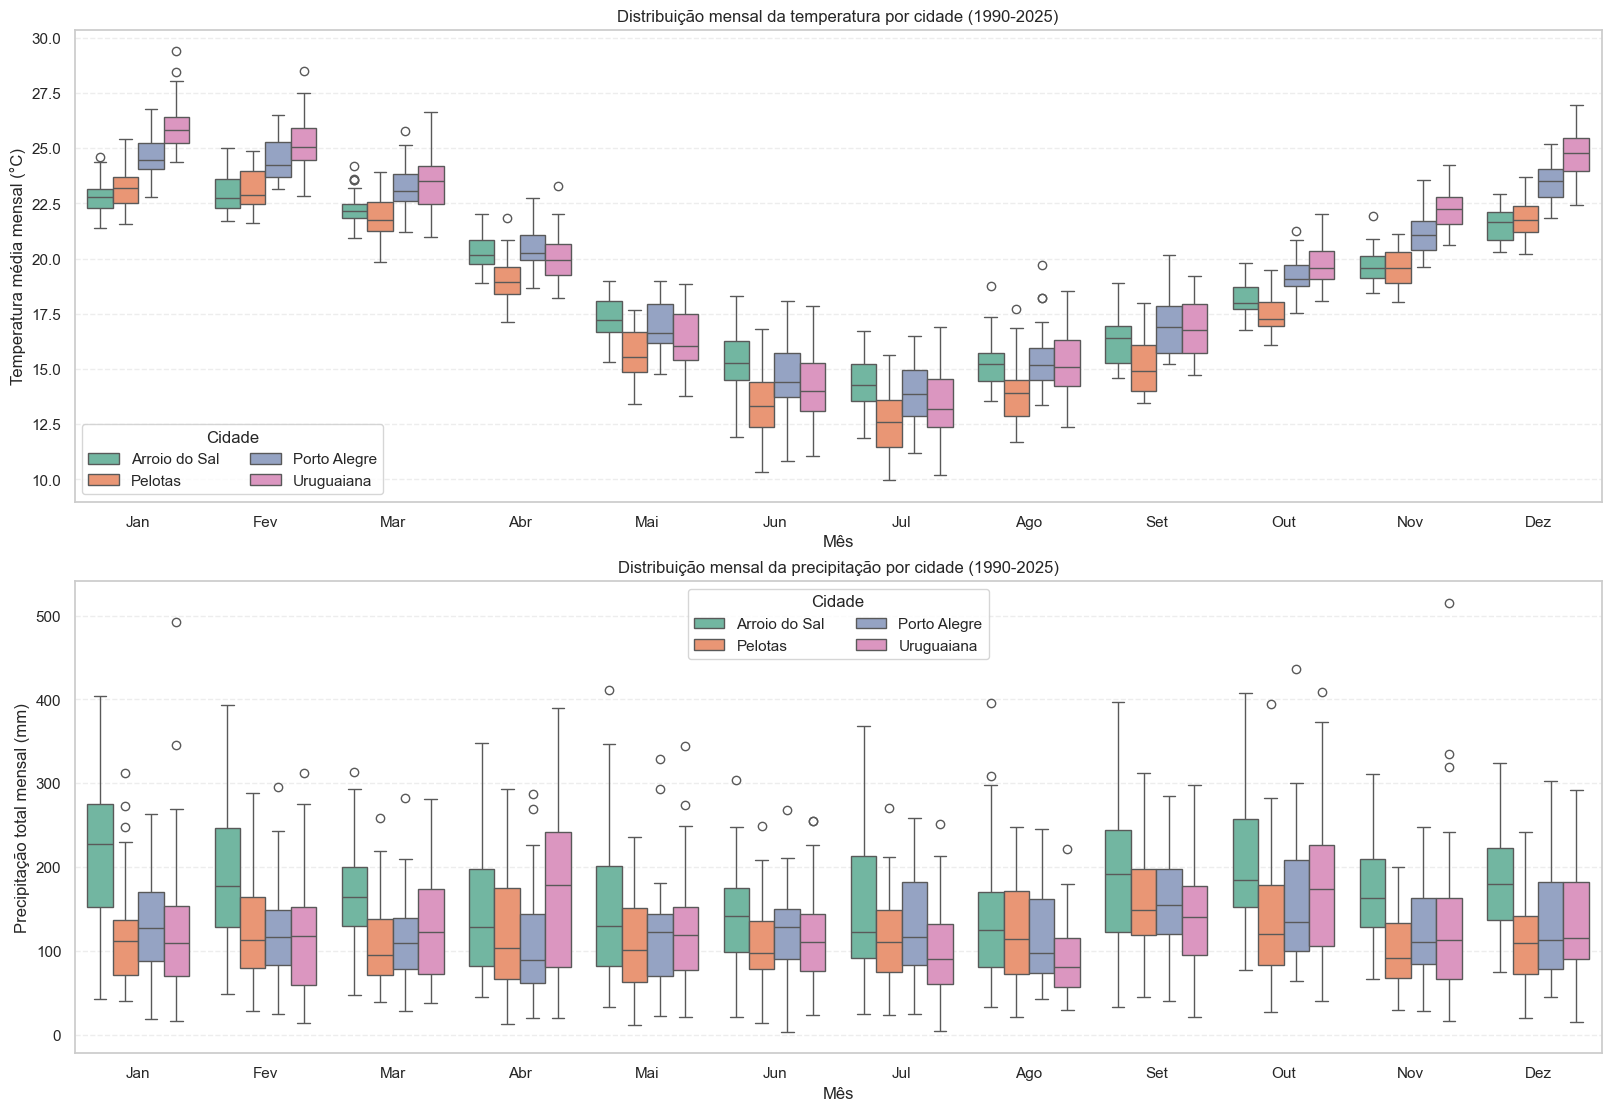

In [22]:
fig, ax = plt.subplots(2, 1, figsize=(16, 11), constrained_layout=True)

sns.boxplot(
    data=df_cidades_mensal, x="MesNome", y="t2m_celsius",
    hue="Cidade", palette="Set2", showfliers=True, ax=ax[0]
)
ax[0].set_title(f"Distribuição mensal da temperatura por cidade ({ANO_INICIAL}-{ANO_FINAL})")
ax[0].set_xlabel("Mês")
ax[0].set_ylabel("Temperatura média mensal (°C)")
ax[0].legend(title="Cidade", ncol=2)
ax[0].grid(axis="y", linestyle="--", alpha=0.35)

sns.boxplot(
    data=df_cidades_mensal, x="MesNome", y="tp_mm_mes",
    hue="Cidade", palette="Set2", showfliers=True, ax=ax[1]
)
ax[1].set_title(f"Distribuição mensal da precipitação por cidade ({ANO_INICIAL}-{ANO_FINAL})")
ax[1].set_xlabel("Mês")
ax[1].set_ylabel("Precipitação total mensal (mm)")
ax[1].legend(title="Cidade", ncol=2)
ax[1].grid(axis="y", linestyle="--", alpha=0.35)
plt.show()

## (3) Quais localidades apresentam maior variabilidade?

É importante separar a variabilidade mensal total da variabilidade interanual. O desvio-padrão dos 432 valores mensais mistura o ciclo sazonal com as diferenças entre anos. Já o desvio-padrão das 36 médias anuais de temperatura descreve a dispersão entre anos, com menor influência da sazonalidade.

Para a precipitação, calcula-se o total anual em cada ano e depois o desvio-padrão desses totais.

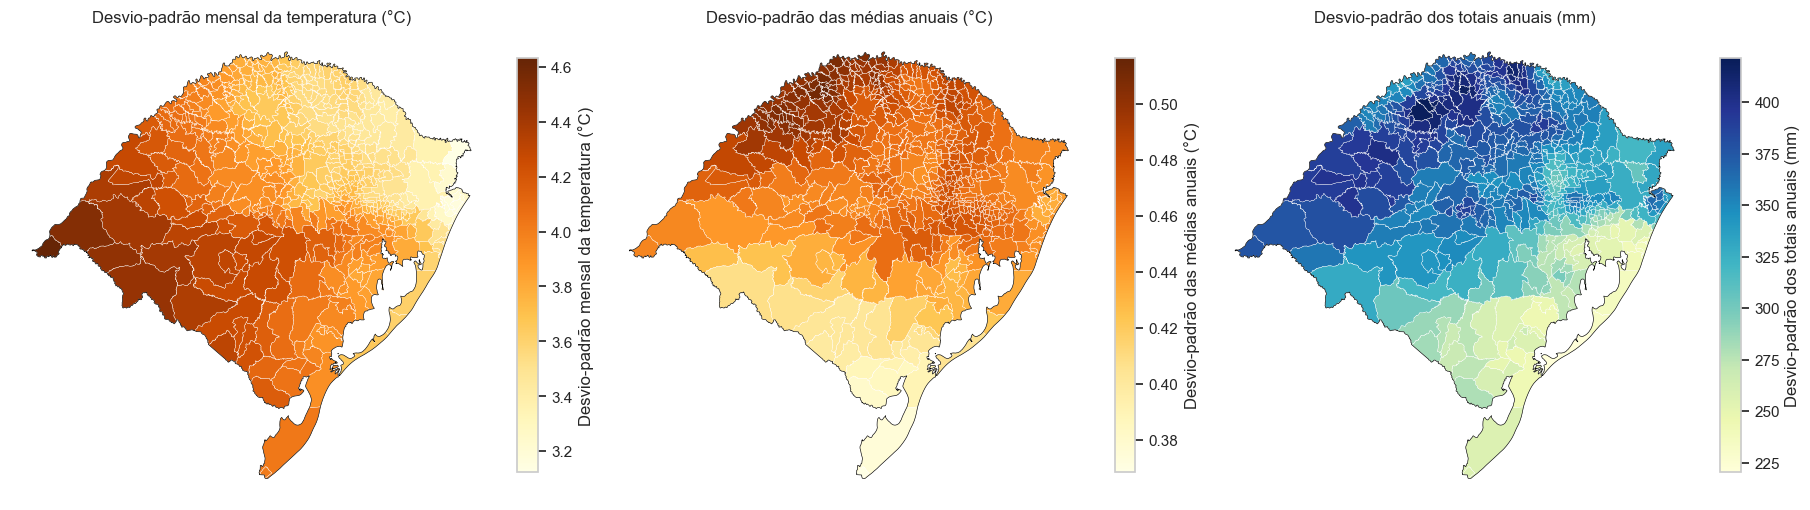

,Municipio,Temp_DesvioPadrao_Mensal_C,Temp_DesvioPadrao_Anual_C,Precip_DesvioPadrao_Anual_mm
44,Boa Vista do Buricá,3.879804,0.516167,376.276164
275,Nova Candelária,3.857577,0.515297,373.587196
393,São José do Inhacorá,3.892495,0.511629,392.718100
457,Três de Maio,3.906282,0.510410,383.974539
121,Crissiumal,3.872206,0.509452,360.906315
409,São Pedro do Butiá,4.064541,0.508326,367.873507
357,Salvador das Missões,4.054252,0.507978,371.035598
128,Derrubadas,3.785855,0.507587,366.770239
192,Horizontina,3.928536,0.507520,361.975619
406,São Paulo das Missões,4.065357,0.507438,358.832249


In [ ]:
colunas_variabilidade = [
    "Temp_DesvioPadrao_Mensal_C",
    "Temp_DesvioPadrao_Anual_C",
    "Precip_DesvioPadrao_Anual_mm",
]

df_variabilidade_municipios = df_municipios[
    ["Municipio"] + colunas_variabilidade
].copy()

gdf_variabilidade = gdf_municipios.copy()

fig, ax = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)

mapas = [
    (
        "Temp_DesvioPadrao_Mensal_C",
        "Desvio-padrão mensal da temperatura (°C)",
        "YlOrBr",
    ),
    (
        "Temp_DesvioPadrao_Anual_C",
        "Desvio-padrão das médias anuais (°C)",
        "YlOrBr",
    ),
    (
        "Precip_DesvioPadrao_Anual_mm",
        "Desvio-padrão dos totais anuais (mm)",
        "YlGnBu",
    ),
]

for eixo, (coluna, titulo, mapa) in zip(ax, mapas):
    gdf_variabilidade.plot(
        column=coluna,
        ax=eixo,
        cmap=mapa,
        legend=True,
        edgecolor="white",
        linewidth=0.25,
        legend_kwds={"label": titulo, "shrink": 0.7},
        missing_kwds={"color": "lightgrey", "label": "Sem dados"},
    )

    rs_poly.boundary.plot(ax=eixo, color="black", linewidth=0.45)
    eixo.set_title(titulo)
    eixo.set_axis_off()

plt.show()

display(
    df_variabilidade_municipios
    .sort_values("Temp_DesvioPadrao_Anual_C", ascending=False)
    .head(10)
)

## (4) Quais localidades apresentam maior frequência ou intensidade de valores extremos?

Por enquanto, analisa-se para Porto Alegre:

(1) distribuição da precipitação mensal de todo o período

(2) comparação da precipitação total de maio entre anos.

A primeira ajuda a visualizar a distribuição geral; a segunda contextualiza maio de 2024 em relação a outros meses de maio.

OBS.: Um valor máximo observado não é, sozinho, uma definição universal de evento climático extremo.

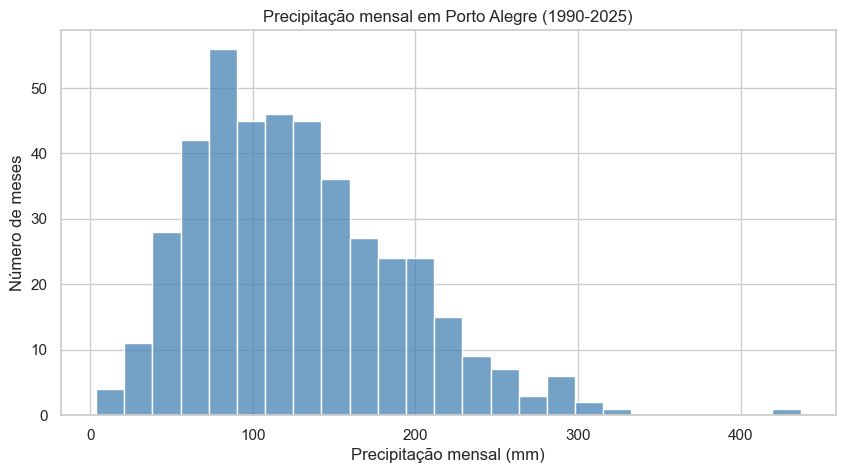

Maior precipitação mensal: 10/1997 (436.8 mm)


In [ ]:
poa_row = rs_mun.loc[rs_mun["nome"].eq("Porto Alegre")].iloc[0]
serie_poa = extrair_serie_poligono(ds, poa_row.geometry, rs_mun.crs)
df_poa = serie_poa.to_dataframe().reset_index()
df_poa["Ano"] = df_poa["time"].dt.year
df_poa["Mes"] = df_poa["time"].dt.month

max_precip = df_poa.loc[df_poa["tp_mm_mes"].idxmax()]
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df_poa, x="tp_mm_mes", bins=25, color="steelblue", ax=ax)
ax.set_title(f"Precipitação mensal em Porto Alegre ({ANO_INICIAL}-{ANO_FINAL})")
ax.set_xlabel("Precipitação mensal (mm)")
ax.set_ylabel("Número de meses")
plt.show()

print("Maior precipitação mensal:", max_precip["time"].strftime("%m/%Y"),
      f"({max_precip['tp_mm_mes']:.1f} mm)")


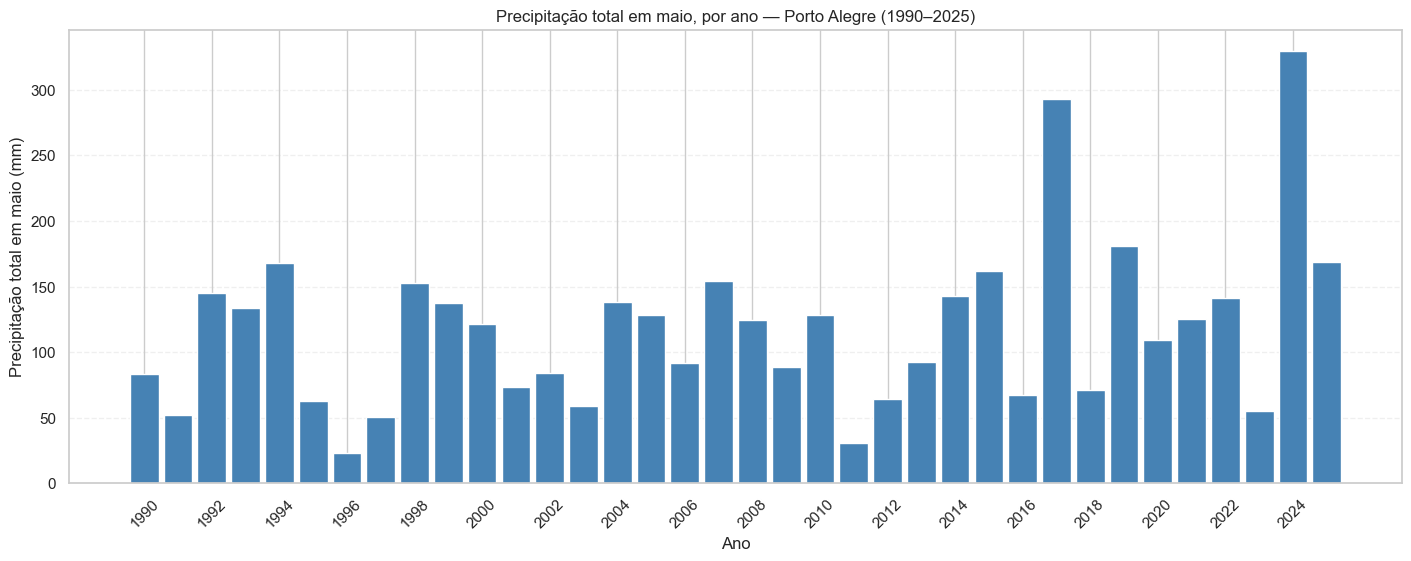

Percentil 95 da precipitação mensal em Porto Alegre: 242.7 mm.
Meses acima do percentil 95: 22 de 432.


In [ ]:
df_maio_poa = (
    df_poa.loc[df_poa["Mes"].eq(5), ["Ano", "tp_mm_mes"]]
    .rename(columns={"tp_mm_mes": "Precipitacao_Maio_mm"})
    .sort_values("Ano")
)

fig, ax = plt.subplots(figsize=(14, 5.5), constrained_layout=True)
ax.bar(df_maio_poa["Ano"], df_maio_poa["Precipitacao_Maio_mm"], color="steelblue", width=0.85)
ax.set_title(f"Precipitação total em maio, por ano - Porto Alegre ({ANO_INICIAL}–{ANO_FINAL})")
ax.set_xlabel("Ano")
ax.set_ylabel("Precipitação total em maio (mm)")
ax.set_xticks(range(ANO_INICIAL, ANO_FINAL + 1, 2))
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()

p95_poa = df_poa["tp_mm_mes"].quantile(0.95)
df_poa["Acima_P95"] = df_poa["tp_mm_mes"] > p95_poa
print(f"Percentil 95 da precipitação mensal em Porto Alegre: {p95_poa:.1f} mm.")
print(f"Meses acima do percentil 95: {int(df_poa['Acima_P95'].sum())} de {len(df_poa)}.")

## (5) Como os padrões variam ao longo dos anos?

esta seção usa séries anuais: média anual da temperatura e total anual da precipitação.

Gerando os gráficos de trajetórias mensais de Porto Alegre...


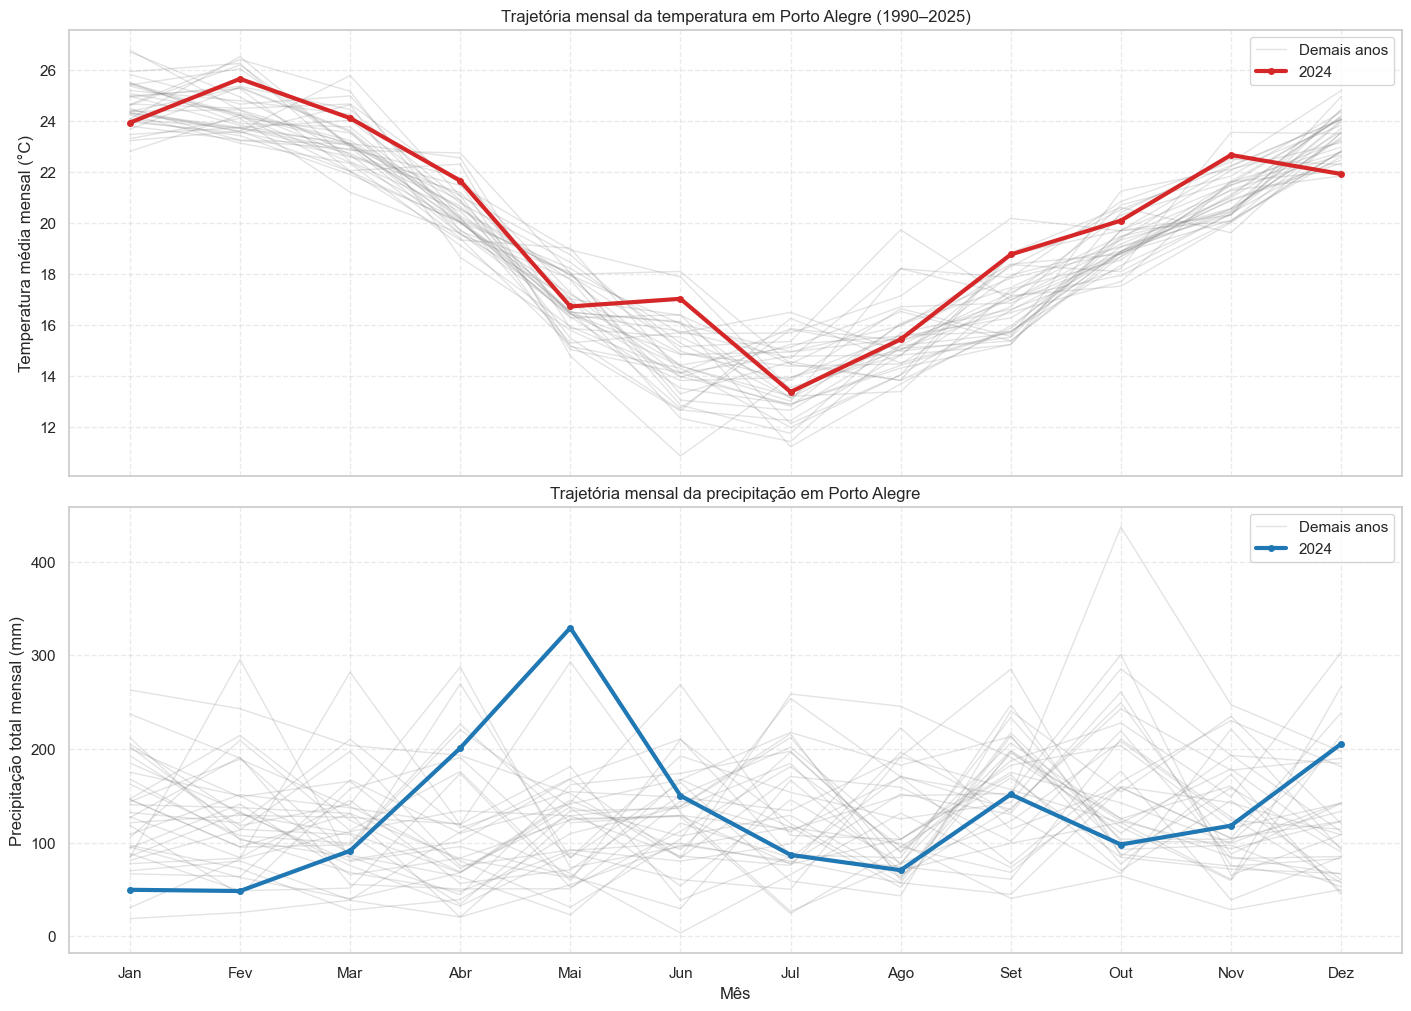

In [ ]:
print("Gerando os gráficos de trajetórias mensais de Porto Alegre...")

meses_nomes = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

fig, ax = plt.subplots(
    2, 1,
    figsize=(14, 10),
    sharex=True,
    constrained_layout=True
)

anos = sorted(df_poa["Ano"].unique())

for ano in anos:
    df_ano = (
        df_poa[df_poa["Ano"] == ano]
        .sort_values("Mes")
    )


    if ano == 2024:
        ax[0].plot(
            df_ano["Mes"], df_ano["t2m_celsius"],
            color="#d62728", linewidth=3,
            marker="o", markersize=4,
            zorder=5, label="2024"
        )
        ax[1].plot(
            df_ano["Mes"], df_ano["tp_mm_mes"],
            color="#1f77b4", linewidth=3,
            marker="o", markersize=4,
            zorder=5, label="2024"
        )
    else:
        ax[0].plot(
            df_ano["Mes"], df_ano["t2m_celsius"],
            color="gray", alpha=0.22,
            linewidth=1, zorder=1,
            label="Demais anos" if ano == anos[0] else None
        )
        ax[1].plot(
            df_ano["Mes"], df_ano["tp_mm_mes"],
            color="gray", alpha=0.22,
            linewidth=1, zorder=1,
            label="Demais anos" if ano == anos[0] else None
        )

ax[0].set_title(
    f"Trajetória mensal da temperatura em Porto Alegre "
    f"({ANO_INICIAL}–{ANO_FINAL})"
)
ax[0].set_ylabel("Temperatura média mensal (°C)")
ax[0].grid(True, linestyle="--", alpha=0.4)
ax[0].legend(loc="best")

ax[1].set_title(
    "Trajetória mensal da precipitação em Porto Alegre"
)
ax[1].set_xlabel("Mês")
ax[1].set_ylabel("Precipitação total mensal (mm)")
ax[1].set_xticks(range(1, 13))
ax[1].set_xticklabels(meses_nomes)
ax[1].grid(True, linestyle="--", alpha=0.4)
ax[1].legend(loc="best")

plt.show()


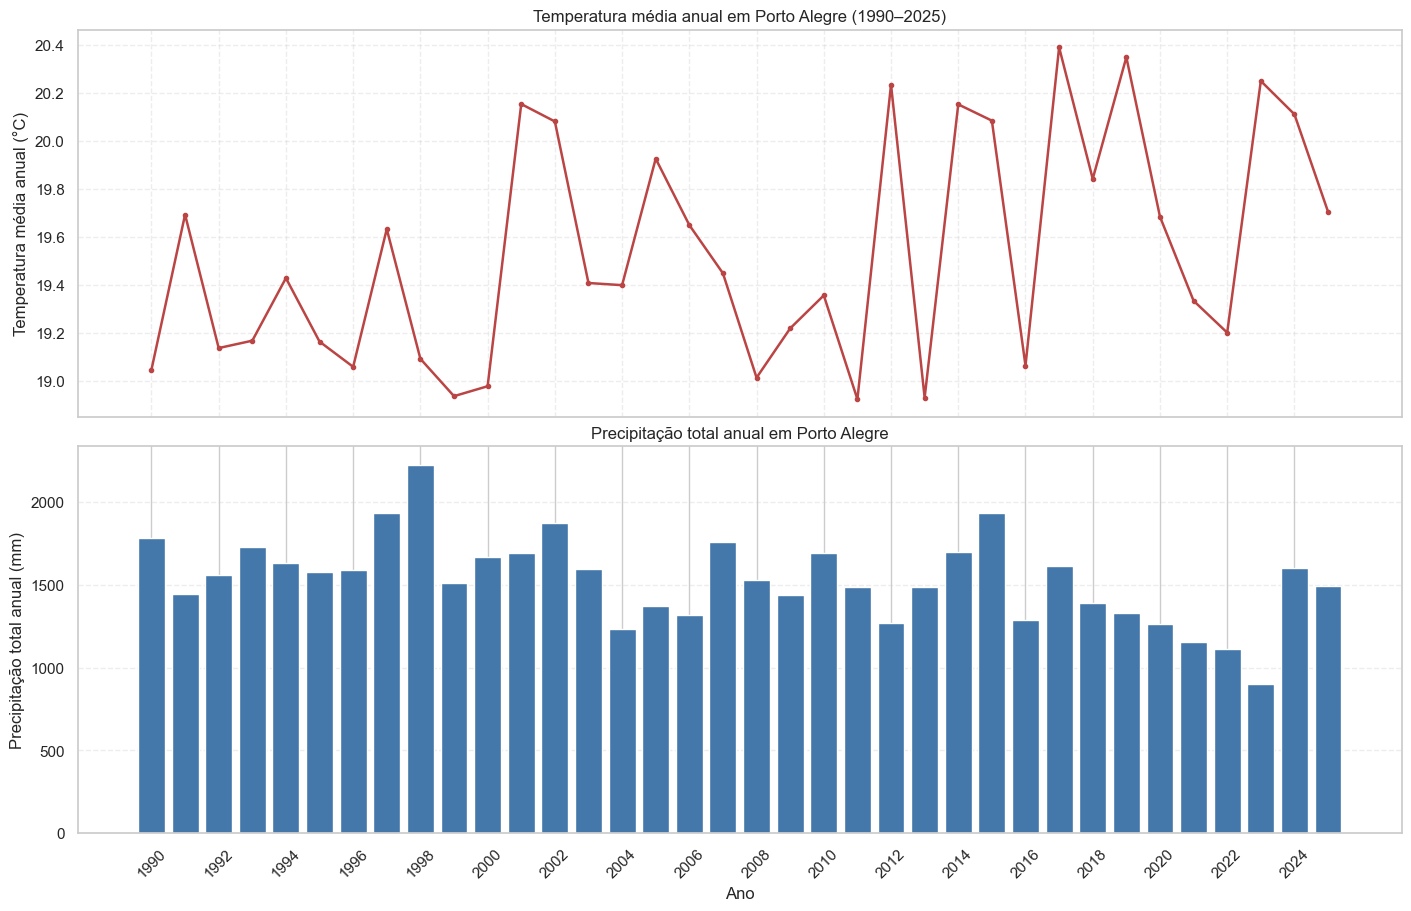

,Ano,Temp_Media_Anual_C,Precip_Total_Anual_mm
count,36.00,36.00,36.00
mean,2007.50,19.54,1531.67
std,10.54,0.47,259.09
min,1990.00,18.93,900.32
25%,1998.75,19.13,1360.67
50%,2007.50,19.42,1543.88
75%,2016.25,19.96,1688.39
max,2025.00,20.39,2223.63


In [ ]:
df_poa["Ano"] = df_poa["time"].dt.year
df_poa_anual = (
    df_poa.groupby("Ano", as_index=False)
    .agg(
        Temp_Media_Anual_C=("t2m_celsius", "mean"),
        Precip_Total_Anual_mm=("tp_mm_mes", "sum"),
    )
)

fig, ax = plt.subplots(2, 1, figsize=(14, 9), sharex=True, constrained_layout=True)
ax[0].plot(
    df_poa_anual["Ano"], df_poa_anual["Temp_Media_Anual_C"],
    color="#BB4444", linewidth=1.8, marker="o", markersize=3
)
ax[0].set_title(f"Temperatura média anual em Porto Alegre ({ANO_INICIAL}–{ANO_FINAL})")
ax[0].set_ylabel("Temperatura média anual (°C)")
ax[0].grid(True, linestyle="--", alpha=0.35)

ax[1].bar(
    df_poa_anual["Ano"], df_poa_anual["Precip_Total_Anual_mm"],
    color="#4477AA", width=0.8
)
ax[1].set_title("Precipitação total anual em Porto Alegre")
ax[1].set_xlabel("Ano")
ax[1].set_ylabel("Precipitação total anual (mm)")
ax[1].set_xticks(range(ANO_INICIAL, ANO_FINAL + 1, 2))
ax[1].tick_params(axis="x", rotation=45)
ax[1].grid(axis="y", linestyle="--", alpha=0.35)
plt.show()

display(df_poa_anual.describe().round(2))

## Separando o Estado do RS em regiões

Usando, inicialmente, dois tipos de divisão:

- Mesorregiões: divisão histórica do IBGE, com sete unidades.
- COREDEs: 28 Conselhos Regionais de Desenvolvimento, definidos para planejamento regional no RS. A malha é fornecida pela Infraestrutura Estadual de Dados Espaciais (IEDE/RS).

### Baixar a malha das sete mesorregiões

In [ ]:
URL_MESORREGIOES = (
    "https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/"
    "malhas_municipais/municipio_2021/UFs/RS/RS_Mesorregioes_2021.zip"
)
ARQ_MESORREGIOES_ZIP = PASTA_DADOS / "RS_Mesorregioes_2021.zip"
PASTA_MESORREGIOES = PASTA_DADOS / "malha_mesorregioes"

if not ARQ_MESORREGIOES_ZIP.exists():
    resposta = requests.get(URL_MESORREGIOES, timeout=120)
    resposta.raise_for_status()
    ARQ_MESORREGIOES_ZIP.write_bytes(resposta.content)

PASTA_MESORREGIOES.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ARQ_MESORREGIOES_ZIP) as zf:
    zf.extractall(PASTA_MESORREGIOES)

shapefiles_meso = list(PASTA_MESORREGIOES.rglob("*.shp"))
if not shapefiles_meso:
    raise FileNotFoundError(
        "Não foi encontrado shapefile no arquivo de mesorregiões do IBGE. "
    )

mesorregioes = gpd.read_file(shapefiles_meso[0]).to_crs("EPSG:4326")
colunas_nome_meso = [c for c in mesorregioes.columns if c.lower() in {"nm_meso", "nome", "name"}]
if not colunas_nome_meso:
    raise KeyError(f"Campo de nome da mesorregião não identificado: {list(mesorregioes.columns)}")
COL_MESO = colunas_nome_meso[0]
mesorregioes = mesorregioes.rename(columns={COL_MESO: "Mesorregiao"})

print(f"Mesorregiões recuperadas: {len(mesorregioes)}")
display(mesorregioes[["Mesorregiao"]])

Mesorregiões recuperadas: 9


,Mesorregiao
0,Noroeste Rio-grandense
1,Nordeste Rio-grandense
2,Centro Ocidental Rio-grandense
3,Centro Oriental Rio-grandense
4,Metropolitana de Porto Alegre
5,Sudoeste Rio-grandense
6,Sudeste Rio-grandense
7,Lagoa Mirim
8,Lagoa dos Patos


C:\Users\rober\AppData\Local\Temp\ipykernel_21840\3574301456.py:34: UserWarning: Esperavam-se 7 mesorregiões, mas foram recuperadas 9. Confira a malha e o campo de regionalização antes de interpretar os mapas.
  warnings.warn(


### Baixar a malha das 28 COREDEs

In [ ]:
URL_COREDE_QUERY = (
    "https://iede.rs.gov.br/server/rest/services/SEPLAG/coredes_atual/MapServer/0/query"
)
params_coredes = {
    "where": "1=1",
    "outFields": "*",
    "outSR": "4326",
    "f": "geojson",
}
res_coredes = requests.get(URL_COREDE_QUERY, params=params_coredes, timeout=120)
res_coredes.raise_for_status()
conteudo_coredes = res_coredes.json()

coredes = gpd.GeoDataFrame.from_features(
    conteudo_coredes["features"], crs="EPSG:4326"
)

if "nome_corede" in coredes.columns:
    coredes["COREDE"] = coredes["nome_corede"].fillna(coredes["corede"])
elif "corede" in coredes.columns:
    coredes["COREDE"] = coredes["corede"]
else:
    raise KeyError(f"Campo de nome do COREDE não encontrado: {list(coredes.columns)}")

coredes = coredes[["COREDE", "geometry"]].drop_duplicates(subset="COREDE").reset_index(drop=True)
print(f"COREDEs recuperados: {len(coredes)}")
display(coredes[["COREDE"]].sort_values("COREDE"))

COREDEs recuperados: 28


,COREDE
2,Alto Jacuí
1,Alto da Serra do Botucaraí
3,Campanha
4,Campos de Cima da Serra
5,Celeiro
6,Central
7,Centro Sul
8,Fronteira Noroeste
9,Fronteira Oeste
10,Hortênsias


###  mesorregiões e COREDEs

Resumo das mesorregiões:


,Temp_Media_C,Precip_Media_Anual_mm,Temp_DesvioPadrao_Mensal_C,Temp_DesvioPadrao_Anual_C,Precip_DesvioPadrao_Anual_mm,Mesorregiao
2,19.03,1704.45,4.12,0.45,360.24,Centro Ocidental Rio-grandense
3,18.65,1682.26,3.98,0.46,328.18,Centro Oriental Rio-grandense
7,18.13,1251.21,4.05,0.38,255.10,Lagoa Mirim
8,19.29,1381.83,3.76,0.43,234.20,Lagoa dos Patos
4,18.73,1638.56,3.72,0.44,273.07,Metropolitana de Porto Alegre
1,16.64,1904.41,3.42,0.45,325.73,Nordeste Rio-grandense
0,19.12,1882.18,3.76,0.47,362.65,Noroeste Rio-grandense
6,17.85,1381.05,4.06,0.40,257.28,Sudeste Rio-grandense
5,19.06,1573.71,4.36,0.43,339.91,Sudoeste Rio-grandense


Resumo dos COREDEs:


,Temp_Media_C,Precip_Media_Anual_mm,Temp_DesvioPadrao_Mensal_C,Temp_DesvioPadrao_Anual_C,Precip_DesvioPadrao_Anual_mm,COREDE
2,18.82,1831.65,3.81,0.46,366.56,Alto Jacuí
1,17.99,1837.02,3.69,0.45,355.49,Alto da Serra do Botucaraí
3,17.91,1461.41,4.29,0.41,296.27,Campanha
4,16.29,1871.87,3.38,0.46,330.02,Campos de Cima da Serra
5,19.92,1927.57,3.77,0.50,384.79,Celeiro
6,18.77,1727.30,4.03,0.45,357.59,Central
7,18.62,1484.16,3.93,0.44,270.29,Centro Sul
8,20.44,1852.16,3.93,0.50,368.42,Fronteira Noroeste
9,19.39,1605.43,4.39,0.44,356.72,Fronteira Oeste
10,16.35,1989.26,3.35,0.45,324.39,Hortênsias


C:\Users\rober\AppData\Local\Temp\ipykernel_21840\976735841.py:100: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  limite_rs = rs_poly.geometry.unary_union


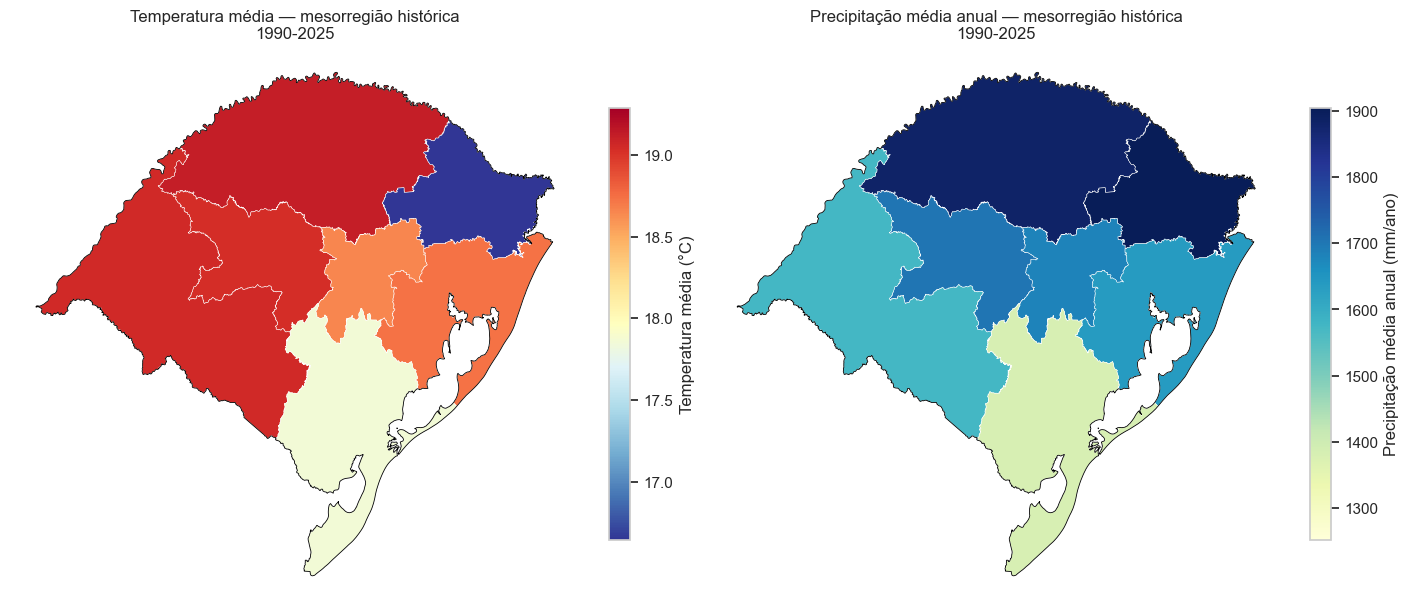

C:\Users\rober\AppData\Local\Temp\ipykernel_21840\976735841.py:100: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  limite_rs = rs_poly.geometry.unary_union


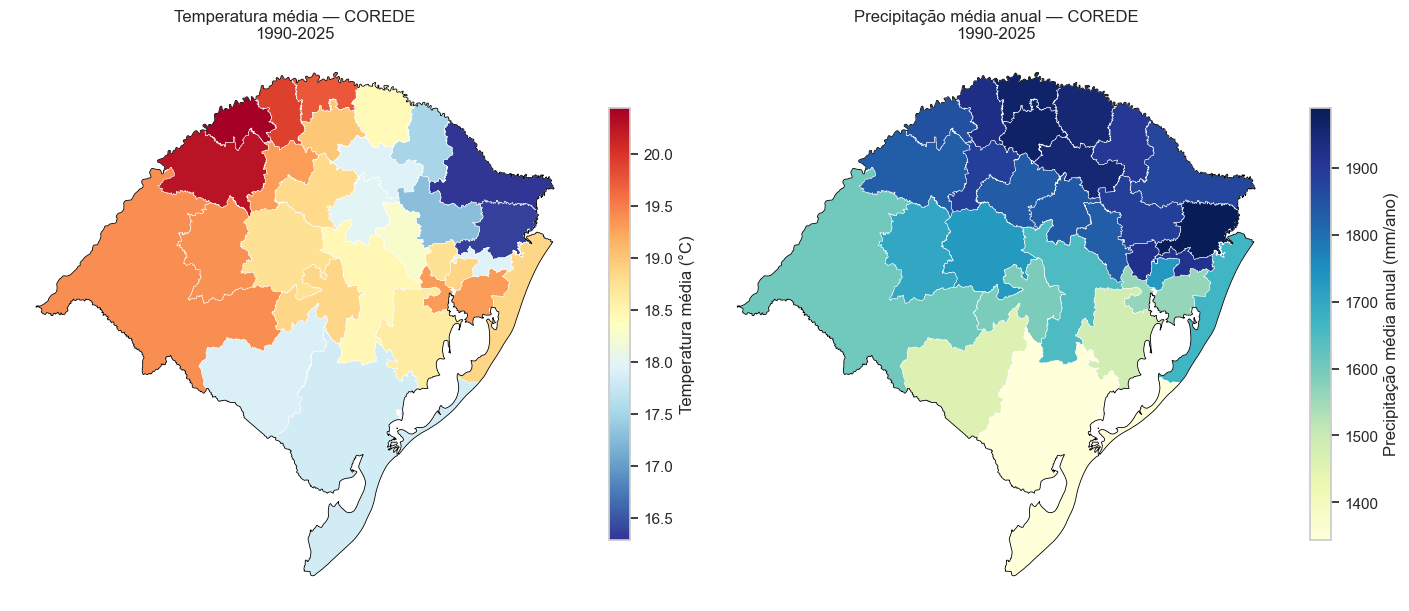

In [26]:
gdf_mesorregioes, df_mesorregioes, serie_mesorregioes = criar_tabela_regional(
    ds, mesorregioes, coluna_nome="Mesorregiao", rotulo="Mesorregiao"
)
gdf_coredes, df_coredes, serie_coredes = criar_tabela_regional(
    ds, coredes, coluna_nome="COREDE", rotulo="COREDE"
)

print("Resumo das mesorregiões:")
display(df_mesorregioes.sort_values("Mesorregiao").round(2))

print("Resumo dos COREDEs:")
display(df_coredes.sort_values("COREDE").round(2))

plotar_mapa_duplo(
    gdf_mesorregioes, "Temp_Media_C", "Precip_Media_Anual_mm",
    "mesorregião histórica", f"{ANO_INICIAL}-{ANO_FINAL}"
)
plotar_mapa_duplo(
    gdf_coredes, "Temp_Media_C", "Precip_Media_Anual_mm",
    "COREDE", f"{ANO_INICIAL}-{ANO_FINAL}"
)

## Referências de dados

- Copernicus Climate Data Store: ERA5-Land monthly averaged data: https://cds.climate.copernicus.eu/
- IBGE: Malhas territoriais e malha municipal: https://www.ibge.gov.br/geociencias/organizacao-do-territorio/malhas-territoriais.html
- IBGE: API de malhas territoriais: https://servicodados.ibge.gov.br/api/docs/malhas?versao=3
- IEDE/RS: Serviço cartográfico dos COREDEs: https://iede.rs.gov.br/server/rest/services/SEPLAG/coredes_atual/MapServer
- Atlas Socioeconômico do RS: COREDEs: https://atlassocioeconomico.rs.gov.br/conselhos-regionais-de-desenvolvimento-coredes